> **Archived.** Early exploration of the M340 data, kept for reference. It was written for an older folder layout (for example it reads `../M340_raw_data.csv` and `../final_database_result.csv`), so it does not run as-is. The maintained version is `algorithm/m340_dd_efrit_tuning.ipynb`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import csv
import re

In [2]:
df_raw=pd.read_csv("../M340_raw_data.csv")

rpm=df_raw["RPM"]

Q1= rpm.quantile(0.25)
Q3= rpm.quantile(0.75)

IQR=Q3-Q1

LowerBound=Q1-(1.5*IQR)
UpperBound=Q3+(1.5*IQR)

outliers=rpm[(rpm<LowerBound) | (rpm >UpperBound)]

df = df_raw[df_raw['RPM'] <= (df_raw['SetPoint'] + 50)].copy()

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 336 entries, 0 to 335
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   SetPoint     336 non-null    float64
 1   RPM          336 non-null    float64
 2   PWM          336 non-null    float64
 3   KP           336 non-null    float64
 4   KI           336 non-null    float64
 5   KD           336 non-null    float64
 6   ScanTime_ms  336 non-null    float64
dtypes: float64(7)
memory usage: 18.5 KB


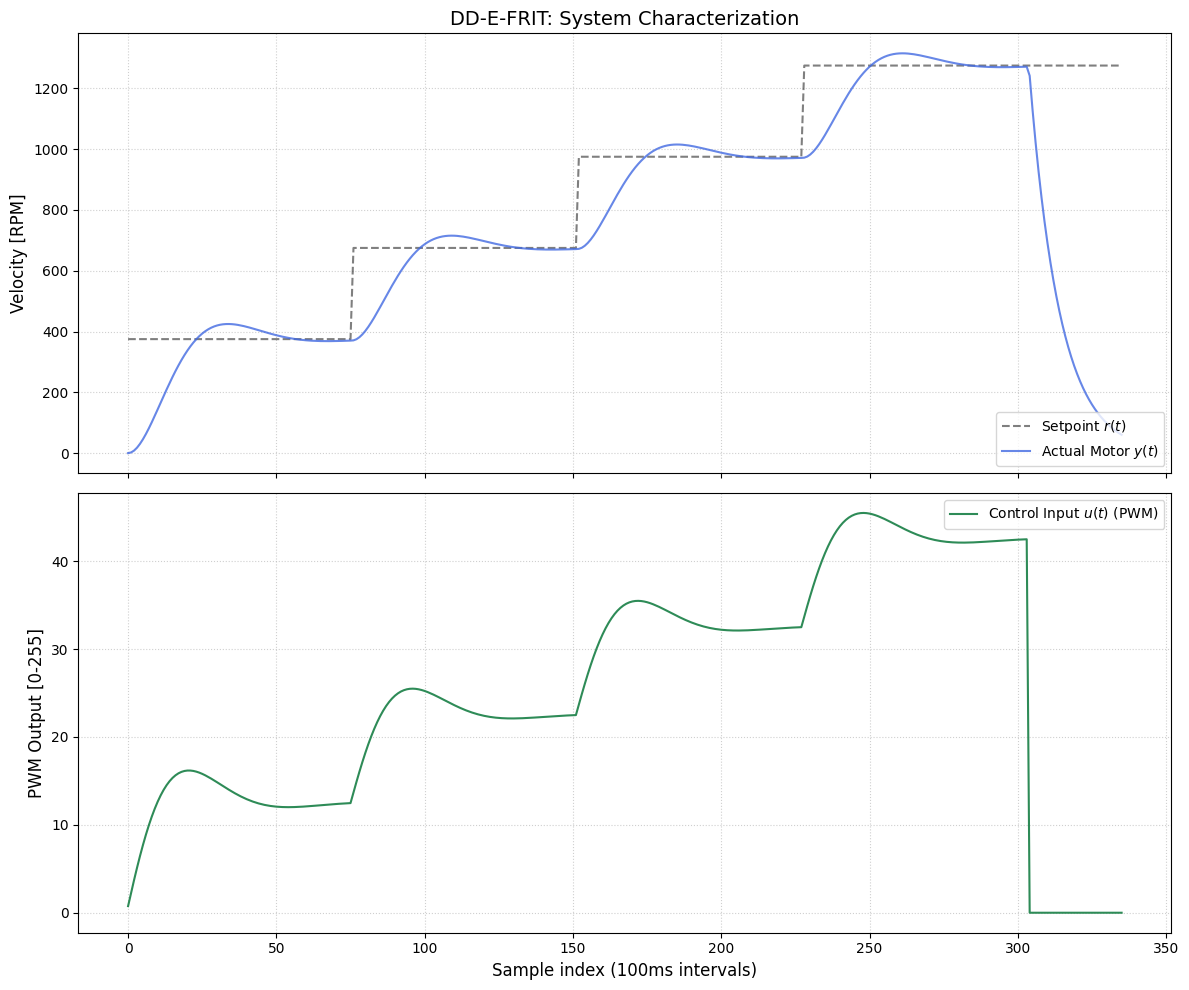

In [3]:
fig,(ax1,ax2)=plt.subplots(2,1,figsize=(12,10),sharex=True)

ax1.plot(df['SetPoint'],'k--',alpha=0.5,label='Setpoint $r(t)$')
ax1.plot(df['RPM'],'royalblue',alpha=0.8,label='Actual Motor $y(t)$')

ax1.set_title("DD-E-FRIT: System Characterization",fontsize=14)
ax1.set_ylabel("Velocity [RPM]",fontsize=12)
ax1.legend(loc='lower right')
ax1.grid(True,linestyle=':',alpha=0.6)

ax2.plot(df['PWM'],'seagreen',label='Control Input $u(t)$ (PWM)')
ax2.set_ylabel("PWM Output [0-255]",fontsize=12)
ax2.set_xlabel("Sample index (100ms intervals)",fontsize=12)
ax2.legend(loc='upper right')
ax2.grid(True,linestyle=':',alpha=0.6)

plt.tight_layout()
plt.show()

In [4]:
df_raw=pd.read_csv("../M340_raw_data.csv")
df_raw.head()

,SetPoint,RPM,PWM,KP,KI,KD,ScanTime_ms
0,375.0,0.000000,0.750000,0.015,0.02,0.0005,5.0
1,375.0,2.105452,2.239157,0.015,0.02,0.0005,5.0
2,375.0,8.163728,3.693198,0.015,0.02,0.0005,5.0
3,375.0,17.710634,5.094359,0.015,0.02,0.0005,5.0
4,375.0,30.274937,6.429152,0.015,0.02,0.0005,5.0


In [5]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 336 entries, 0 to 335
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   SetPoint     336 non-null    float64
 1   RPM          336 non-null    float64
 2   PWM          336 non-null    float64
 3   KP           336 non-null    float64
 4   KI           336 non-null    float64
 5   KD           336 non-null    float64
 6   ScanTime_ms  336 non-null    float64
dtypes: float64(7)
memory usage: 18.5 KB


In [6]:
df_raw.describe()

,SetPoint,RPM,PWM,KP,KI,KD,ScanTime_ms
count,336.000000,336.000000,336.000000,3.360000e+02,3.360000e+02,3.360000e+02,336.0
mean,867.857143,746.569320,24.975252,1.500000e-02,2.000000e-02,5.000000e-04,5.0
std,345.818765,371.366703,13.604198,1.737311e-18,3.474621e-18,1.085819e-19,0.0
min,375.000000,0.000000,0.000000,1.500000e-02,2.000000e-02,5.000000e-04,5.0
25%,675.000000,406.473030,13.662379,1.500000e-02,2.000000e-02,5.000000e-04,5.0
50%,975.000000,703.302063,24.333544,1.500000e-02,2.000000e-02,5.000000e-04,5.0
75%,1275.000000,1009.032974,34.989745,1.500000e-02,2.000000e-02,5.000000e-04,5.0
max,1275.000000,1315.265869,45.478962,1.500000e-02,2.000000e-02,5.000000e-04,5.0


In [7]:
df_raw.nunique()

SetPoint         4
RPM            336
PWM            305
KP               1
KI               1
KD               1
ScanTime_ms      1
dtype: int64

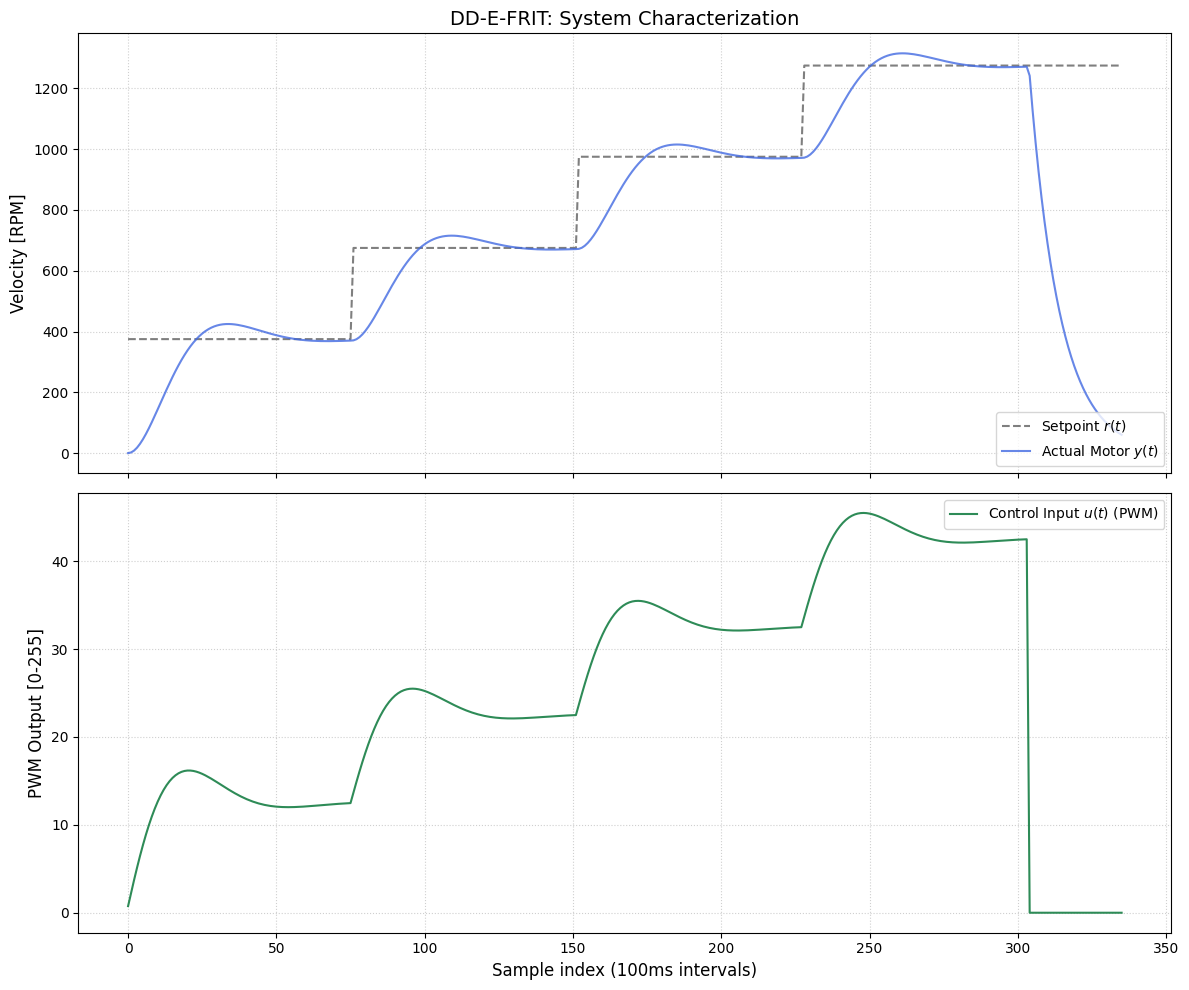

In [8]:
fig,(ax1,ax2)=plt.subplots(2,1,figsize=(12,10),sharex=True)

ax1.plot(df_raw['SetPoint'],'k--',alpha=0.5,label='Setpoint $r(t)$')
ax1.plot(df_raw['RPM'],'royalblue',alpha=0.8,label='Actual Motor $y(t)$')

ax1.set_title("DD-E-FRIT: System Characterization",fontsize=14)
ax1.set_ylabel("Velocity [RPM]",fontsize=12)
ax1.legend(loc='lower right')
ax1.grid(True,linestyle=':',alpha=0.6)

ax2.plot(df_raw['PWM'],'seagreen',label='Control Input $u(t)$ (PWM)')
ax2.set_ylabel("PWM Output [0-255]",fontsize=12)
ax2.set_xlabel("Sample index (100ms intervals)",fontsize=12)
ax2.legend(loc='upper right')
ax2.grid(True,linestyle=':',alpha=0.6)

plt.tight_layout()
plt.show()

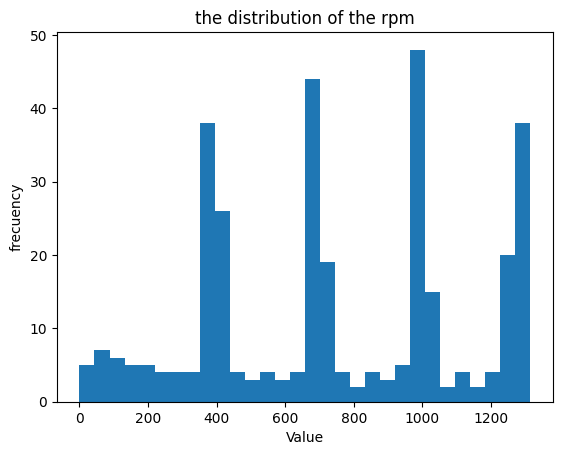

In [9]:
rpm=df_raw["RPM"]

plt.hist(rpm, bins=30)
plt.xlabel("Value")
plt.ylabel("frecuency")
plt.title("the distribution of the rpm")
plt.show()

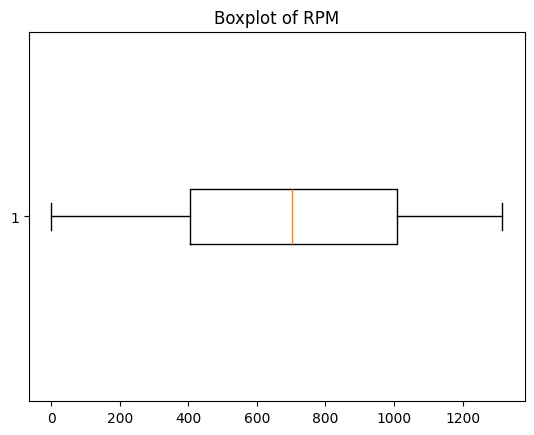

In [10]:
plt.boxplot(rpm, vert=False)
plt.title("Boxplot of RPM")
plt.show()

In [11]:
Q1= rpm.quantile(0.25)
Q3= rpm.quantile(0.75)

IQR=Q3-Q1

LowerBound=Q1-(1.5*IQR)
UpperBound=Q3+(1.5*IQR)

outliers=rpm[(rpm<LowerBound) | (rpm >UpperBound)]

print(outliers.values)

[]


In [41]:
df=df_raw[(df_raw['RPM'] >= LowerBound) & (df_raw['RPM'] <= UpperBound)]

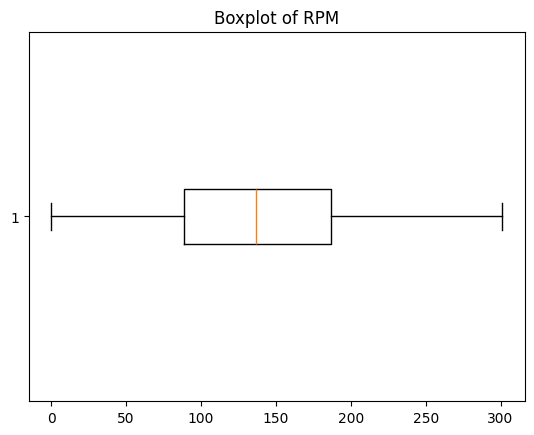

In [42]:
rpm=df["RPM"]

plt.boxplot(rpm, vert=False)
plt.title("Boxplot of RPM")
plt.show()

In [43]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1199 entries, 0 to 1198
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   SetPoint  1199 non-null   float64
 1   RPM       1199 non-null   float64
 2   PWM       1199 non-null   int64  
 3   Kp        1199 non-null   float64
 4   Ki        1199 non-null   float64
 5   Kd        1199 non-null   float64
dtypes: float64(5), int64(1)
memory usage: 56.3 KB


In [44]:
ny=2
nu=2
k=10

setpoint=df["SetPoint"].values
rpm=df["RPM"].values
pwm=df["PWM"].values

def buildVector(i):
    return [setpoint[i+1], setpoint[i], rpm[i], rpm[i-1], pwm[i-1], pwm[i-2]]

ranges=[
    setpoint.max()-setpoint.min(),
    setpoint.max()-setpoint.min(),
    rpm.max()-rpm.min(),
    rpm.max()-rpm.min(),
    pwm.max()-pwm.min(),
    pwm.max()-pwm.min(),
]

def distanceCalc(queryPhi, infoPhi):
    total=0

    for q, d, r in zip(queryPhi, infoPhi, ranges):
        total+=abs(q-d)/r
    
    return total


for i in range (2, len(setpoint)-1):
    distances=[]

    infoVector=buildVector(i)

    for j in range(2, len(setpoint)-1):
        if i==j:
            continue
        
        query=buildVector(j)

        d=distanceCalc(query, infoVector)
        distances.append((d,j))

    distances.sort(key=lambda x: x[0])
    neighbours=distances[:k]

    print(f"{i}: neib {neighbours}")



2: neib [(np.float64(0.09016393442622951), 3), (np.float64(0.1844262295081967), 4), (np.float64(0.2786885245901639), 5), (np.float64(0.36885245901639346), 6), (np.float64(0.45901639344262296), 7), (np.float64(0.6007842710092044), 9), (np.float64(0.6130793529764174), 8), (np.float64(0.6557377049180328), 10), (np.float64(0.8081259190675889), 12), (np.float64(0.9529709710800065), 15)]
3: neib [(np.float64(0.09016393442622951), 2), (np.float64(0.0942622950819672), 4), (np.float64(0.1885245901639344), 5), (np.float64(0.2786885245901639), 6), (np.float64(0.36885245901639346), 7), (np.float64(0.5106203365829748), 9), (np.float64(0.522915418550188), 8), (np.float64(0.5655737704918032), 10), (np.float64(0.7179619846413594), 12), (np.float64(0.862807036653777), 15)]
4: neib [(np.float64(0.0942622950819672), 3), (np.float64(0.0942622950819672), 5), (np.float64(0.1844262295081967), 2), (np.float64(0.1844262295081967), 6), (np.float64(0.27459016393442626), 7), (np.float64(0.4163580415010076), 9), (

In [45]:
# t=2
# 1:(0,2269, 5), 2:(0.24115, 6), 3:(0.258, 9)
# d1=0.2269
# d2=0.24115
# d3=0.258
# exp(-d1)
# exp(-d2)
# exp(-d3)

def expD(d):
    return np.exp(-d)

def weightCalc (d, total_exp):
    return d/total_exp


exp_values=[]

for i in range (len(neighbours)):
    d=neighbours[i][0]
    exp_values.append(expD(d))

total=sum(exp_values)


weights=[]
for i in range (len(neighbours)):
    weights.append(weightCalc(exp_values[i], total))

print(f"Weighs: {weights}")
print(f"Weights Sum: {sum(weights):.6f}")

kp=df["Kp"].values
ki=df["Ki"].values
kd=df["Kd"].values

weighted_kp=0
weighted_ki=0
weighted_kd=0


for i in range (len(neighbours)):
    row_idx=neighbours[i][1]
    weighted_kp+=weights[i]*kp[row_idx]
    weighted_ki+=weights[i]*ki[row_idx]
    weighted_kd+=weights[i]*kd[row_idx]

print (f"Weight Kp: {weighted_kp}")
print (f"Weight Ki: {weighted_ki}")
print (f"Weight Kd: {weighted_kd}")

print (exp_values)
print(total)

    

Weighs: [np.float64(0.10168151786118075), np.float64(0.10150169506568983), np.float64(0.10061692949281181), np.float64(0.10016175828420266), np.float64(0.10000640749776973), np.float64(0.09977383298052586), np.float64(0.09959738390756948), np.float64(0.09916842671468848), np.float64(0.09876283044396696), np.float64(0.09872921775159443)]
Weights Sum: 1.000000
Weight Kp: 0.8
Weight Ki: 1.5
Weight Kd: 0.05
[np.float64(0.9660333308850636), np.float64(0.9643249101439972), np.float64(0.9559191245951754), np.float64(0.9515947344009221), np.float64(0.9501188119242503), np.float64(0.9479092192637747), np.float64(0.9462328508414195), np.float64(0.9421575089841935), np.float64(0.9383041094220961), np.float64(0.9379847693703772)]
9.50057936983127


In [46]:
def calculateReferenceModel (ts, risetime, damping):
    rho=ts/risetime
    mu=0.25*(1-damping)+0.51*damping
    p1=-2*np.exp(-rho/(2*mu))*np.cos(np.sqrt(4*mu-1)*rho/(2*mu))
    p2=np.exp(-rho/mu)
    P_1=1+p1+p2

    return p1, p2, P_1 

ts=0.1  #temp parameters for the ideal model
risetime=1
damping=0.8

check=calculateReferenceModel(ts, risetime, damping)

if check[2]==1+check[0]+check[1]:
    print("pass")
else:
    print("fail")

print (check)

pass
(np.float64(-1.7842723884995897), np.float64(0.8038515940517704), np.float64(0.019579205552180734))


In [47]:
def checkDifferentials(y0, u0, i):
    dy0=y0[i]-y0[i-1]
    du0=u0[i]-u0[i-1]

    d2y=y0[i]-2*y0[i-1]+y0[i-2]

    return dy0, du0, d2y


i=2
dy0, du0, d2y =checkDifferentials(rpm, pwm, i)

print (f"At t={i}")
print (f"RPM velocity: {dy0}")
print (f"RPM acceleration: {d2y}")
print (f"PWM Change: {du0}")


At t=2
RPM velocity: 0.0
RPM acceleration: 0.0
PWM Change: 11


In [48]:
r_tilda=list(np.zeros(len(setpoint)))
y_ref=list(np.zeros(len(setpoint)))


for i in range(2, len(setpoint)):
    dy0, du0, d2y=checkDifferentials(rpm, pwm, i)
    p1, p2, P_1=calculateReferenceModel(ts, risetime, damping)

    r_tilda[i]=rpm[i]+(du0+kp[i]*dy0+kd[i]*d2y)/ki[i]
    y_ref[i]=r_tilda[i-1]*P_1-y_ref[i-1]*p1-y_ref[i-2]*p2

print(r_tilda[:5])
print(y_ref[-5:])

[np.float64(0.0), np.float64(0.0), np.float64(7.333333333333333), np.float64(8.0), np.float64(7.333333333333333)]
[np.float64(223.1953197184843), np.float64(223.54689376890073), np.float64(223.8187993842387), np.float64(224.1472992608288), np.float64(224.34191110888867)]


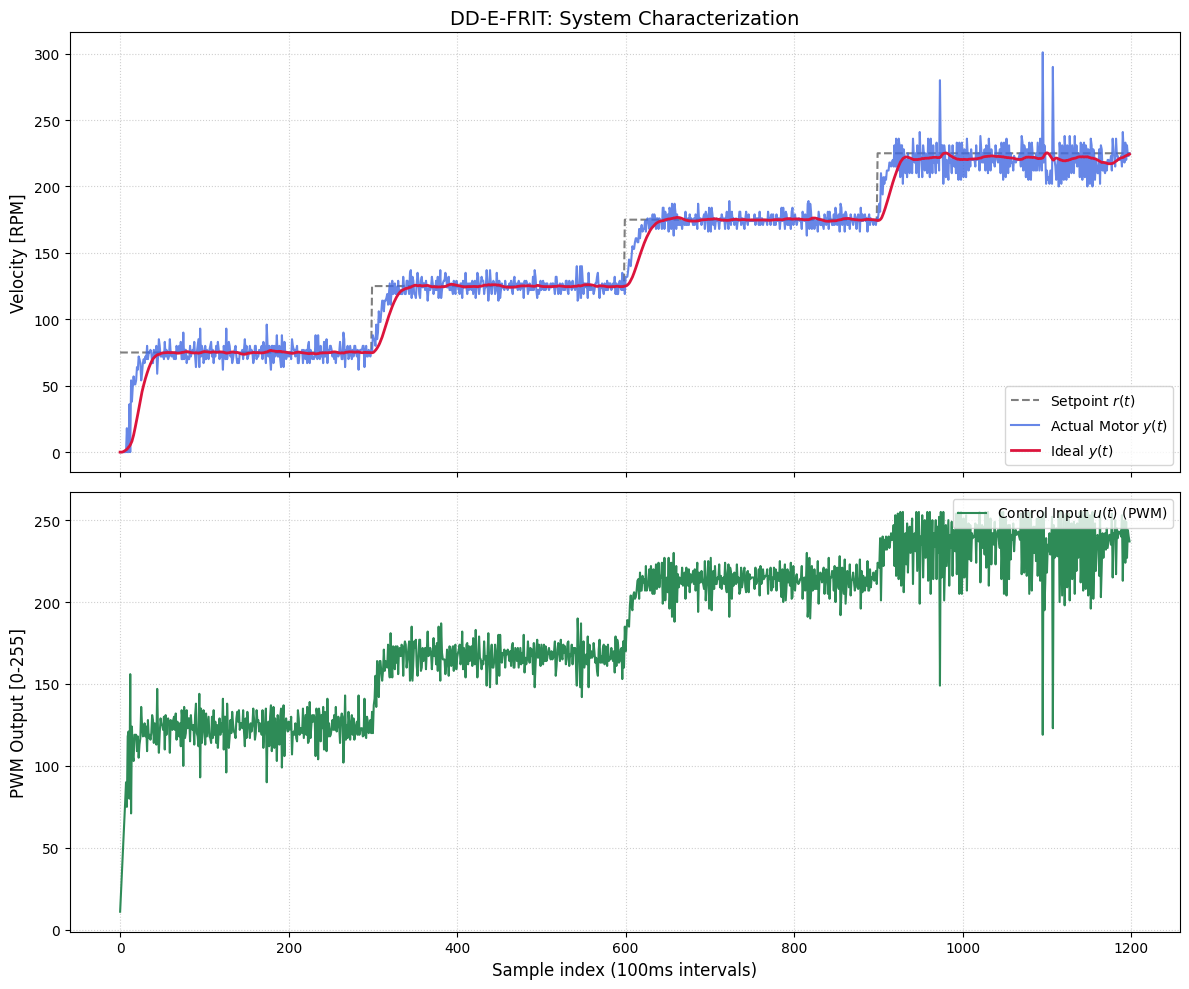

In [49]:
fig,(ax1,ax2)=plt.subplots(2,1,figsize=(12,10),sharex=True)

ax1.plot(df['SetPoint'],'k--',alpha=0.5,label='Setpoint $r(t)$')
ax1.plot(df['RPM'],'royalblue',alpha=0.8,label='Actual Motor $y(t)$')
ax1.plot(y_ref,'crimson',linewidth=2,label='Ideal $y(t)$')

ax1.set_title("DD-E-FRIT: System Characterization",fontsize=14)
ax1.set_ylabel("Velocity [RPM]",fontsize=12)
ax1.legend(loc='lower right')
ax1.grid(True,linestyle=':',alpha=0.6)

ax2.plot(df['PWM'],'seagreen',label='Control Input $u(t)$ (PWM)')
ax2.set_ylabel("PWM Output [0-255]",fontsize=12)
ax2.set_xlabel("Sample index (100ms intervals)",fontsize=12)
ax2.legend(loc='upper right')
ax2.grid(True,linestyle=':',alpha=0.6)

plt.tight_layout()
plt.show()

In [50]:
error=np.zeros(len(setpoint))

x0=list(np.zeros(len(setpoint)))
kp_grad=0
ki_grad=0
kd_grad=0
error=rpm-y_ref


for i in range(2, len(setpoint)-1):
    dy0, du0, d2y=checkDifferentials(rpm, pwm, i)
    x0[i]=du0+kp[i]*dy0+kd[i]*d2y

    kp_grad=kp_grad-error[i+1]*P_1*dy0/ki[i]
    ki_grad=ki_grad+error[i+1]*P_1*x0[i]/(ki[i]**2)
    kd_grad=kd_grad-error[i+1]*P_1*d2y/ki[i]

kp_grad=kp_grad/len(setpoint)
ki_grad=ki_grad/len(setpoint)
kd_grad=kd_grad/len(setpoint)

print (kp_grad)
print (ki_grad)
print (kd_grad)

0.030462903168939383
-0.017161170300357798
-0.21072220288839086


In [51]:
max_epochs=3000
diff_u_tilda=np.zeros(len(setpoint))
cost_hist=np.zeros(max_epochs)

lr_kp=0.0001
lr_ki=0.00001
lr_kd=0.00001

kp_opt=weighted_kp
ki_opt=weighted_ki
kd_opt=weighted_kd
fs=0
l=0 # lambda [0.1-1]

fs=np.var(setpoint-rpm)/np.var(np.diff(pwm))

p1, p2, P_1=calculateReferenceModel(ts, risetime, damping)

for epoch in range(max_epochs):
    epoch_cost=0
    kp_grad=0
    ki_grad=0
    kd_grad=0
    

    for i in range(2, len(setpoint)):
        dy0, du0, d2y=checkDifferentials(rpm, pwm, i)

        r_tilda[i]=rpm[i]+(du0+kp_opt*dy0+kd_opt*d2y)/ki_opt
        y_ref[i]=r_tilda[i-1]*P_1-y_ref[i-1]*p1-y_ref[i-2]*p2
    
    error=rpm-y_ref
    
    for i in range(2, len(setpoint)-1):
        dy0, du0, d2y=checkDifferentials(rpm, pwm, i)

        dy_ref=y_ref[i]-y_ref[i-1]
        d2y_ref=y_ref[i]-2*y_ref[i-1]+y_ref[i-2]

        x0[i]=du0+kp_opt*dy0+kd_opt*d2y

        diff_u_tilda[i]=ki_opt*(r_tilda[i]-y_ref[i])-kp_opt*dy_ref-kd_opt*d2y_ref

        epoch_cost+=(0.5*(rpm[i]-y_ref[i])**2+(l*fs*(diff_u_tilda[i])**2)/2)

        kp_grad=kp_grad-error[i+1]*P_1*dy0/ki_opt+l * fs*diff_u_tilda[i]*(dy0-dy_ref)
        ki_grad=ki_grad+error[i+1]*P_1*x0[i]/(ki_opt**2)+l * fs*diff_u_tilda[i]*((r_tilda[i]-y_ref[i])-(x0[i]/ki_opt))
        kd_grad=kd_grad-error[i+1]*P_1*d2y/ki_opt+l * fs*diff_u_tilda[i]*(d2y-d2y_ref)


    kp_grad=kp_grad/len(setpoint)
    ki_grad=ki_grad/len(setpoint)
    kd_grad=kd_grad/len(setpoint)
    
    kp_opt=kp_opt-(lr_kp*kp_grad)
    ki_opt=ki_opt-(lr_ki*ki_grad)
    kd_opt=kd_opt-(lr_kd*kd_grad)

    if kp_opt<0.2: kp_opt=0.2
    if ki_opt<0.01: ki_opt=0.05
    if kd_opt<0.3: kd_opt=0.3 

    cost_hist[epoch]=epoch_cost/len(setpoint)

    print(f"Epoch {epoch} new PID: {kp_opt:.4f}, {ki_opt:.4f}, {kd_opt:.4f}")

for epoch in range(max_epochs):
    print(f"Epoch {epoch} cost: {cost_hist[epoch]}")



Epoch 0 new PID: 0.8000, 1.5000, 0.3000
Epoch 1 new PID: 0.8000, 1.5000, 0.3000
Epoch 2 new PID: 0.8000, 1.5000, 0.3000
Epoch 3 new PID: 0.8000, 1.5000, 0.3000
Epoch 4 new PID: 0.8000, 1.5000, 0.3000
Epoch 5 new PID: 0.8000, 1.5000, 0.3000
Epoch 6 new PID: 0.8000, 1.5000, 0.3000
Epoch 7 new PID: 0.8000, 1.5000, 0.3000
Epoch 8 new PID: 0.8000, 1.5000, 0.3000
Epoch 9 new PID: 0.8000, 1.5000, 0.3000
Epoch 10 new PID: 0.8000, 1.5000, 0.3000
Epoch 11 new PID: 0.8000, 1.5000, 0.3000
Epoch 12 new PID: 0.8000, 1.5000, 0.3000
Epoch 13 new PID: 0.8000, 1.5000, 0.3000
Epoch 14 new PID: 0.7999, 1.5000, 0.3000
Epoch 15 new PID: 0.7999, 1.5000, 0.3000
Epoch 16 new PID: 0.7999, 1.5000, 0.3000
Epoch 17 new PID: 0.7999, 1.5000, 0.3000
Epoch 18 new PID: 0.7999, 1.5000, 0.3000
Epoch 19 new PID: 0.7999, 1.5000, 0.3000
Epoch 20 new PID: 0.7999, 1.5000, 0.3000
Epoch 21 new PID: 0.7999, 1.5000, 0.3000
Epoch 22 new PID: 0.7999, 1.5000, 0.3000
Epoch 23 new PID: 0.7999, 1.5000, 0.3000
Epoch 24 new PID: 0.7999, 

In [52]:
print(cost_hist[:10])
print("\n")
print(cost_hist[-10:])

[45.09817822 45.11098449 45.11099036 45.11099623 45.1110021  45.11100797
 45.11101384 45.11101971 45.11102558 45.11103145]


[45.12850731 45.12851316 45.12851902 45.12852487 45.12853073 45.12853658
 45.12854244 45.12854829 45.12855415 45.12856   ]


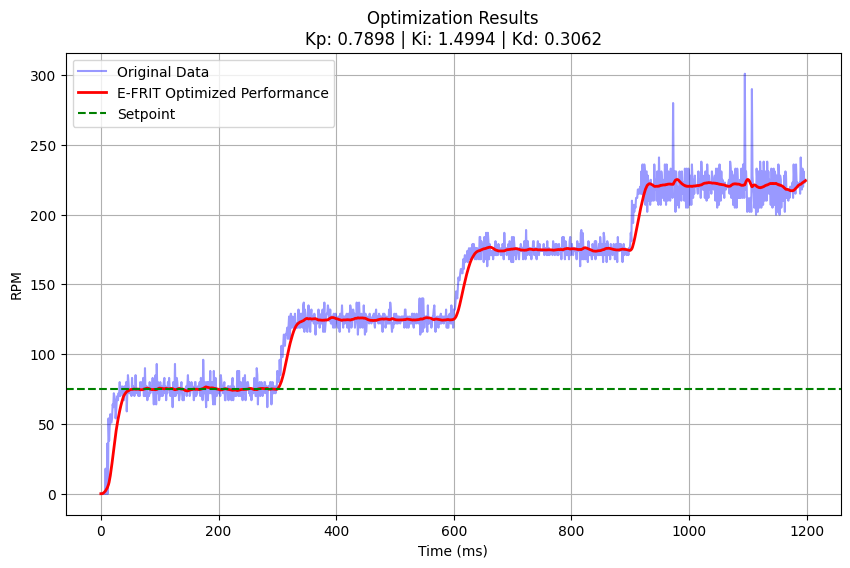

In [53]:
plt.figure(figsize=(10, 6))
plt.plot(rpm, label="Original Data", color='blue', alpha=0.4)
plt.plot(y_ref, label="E-FRIT Optimized Performance", color='red', linewidth=2)
plt.axhline(y=setpoint[0], color='green', linestyle='--', label="Setpoint")
plt.title(f"Optimization Results\nKp: {kp_opt:.4f} | Ki: {ki_opt:.4f} | Kd: {kd_opt:.4f}")
plt.xlabel("Time (ms)")
plt.ylabel("RPM")
plt.legend()
plt.grid(True)
plt.show()

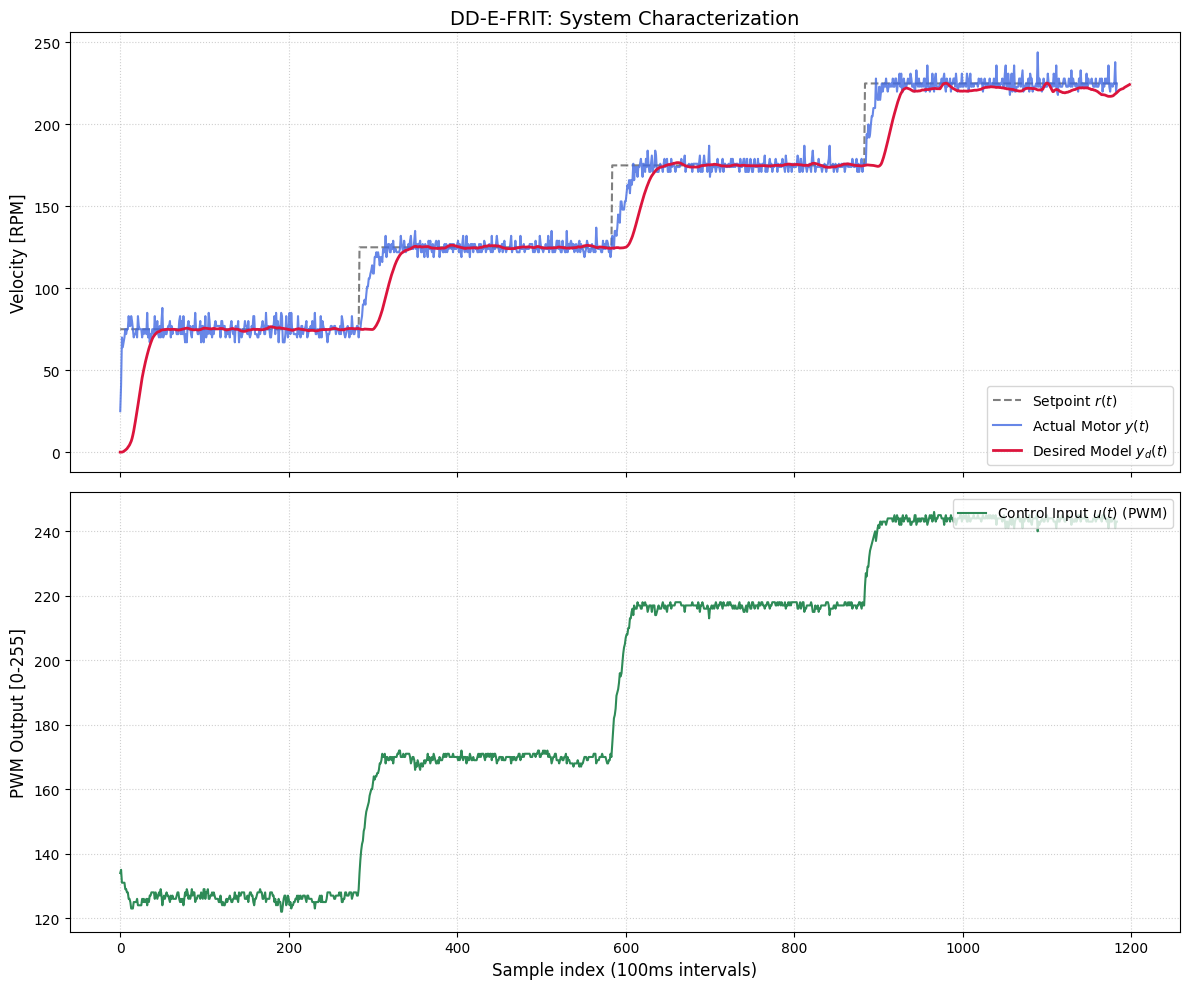

In [57]:
df2=pd.read_csv("../final_database_result.csv")


fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

ax1.plot(df2['SetPoint'], 'k--', alpha=0.5, label='Setpoint $r(t)$')
ax1.plot(df2['RPM'], 'royalblue', alpha=0.8, label='Actual Motor $y(t)$')
ax1.plot(y_ref, 'crimson', linewidth=2, label='Desired Model $y_d(t)$')

ax1.set_title("DD-E-FRIT: System Characterization", fontsize=14)
ax1.set_ylabel("Velocity [RPM]", fontsize=12)
ax1.legend(loc='lower right')
ax1.grid(True, linestyle=':', alpha=0.6)

ax2.plot(df2['PWM'], 'seagreen', label='Control Input $u(t)$ (PWM)')
ax2.set_ylabel("PWM Output [0-255]", fontsize=12)
ax2.set_xlabel("Sample index (100ms intervals)", fontsize=12)
ax2.legend(loc='upper right')
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()